# Projet : Prédiction d'une maladie cardiovasculaire

## I - Introduction

* L'objectif de ce projet est de prédire l'apparition d'une maladie cardiovasculaire chez des patients en se basant sur leurs données médicales.

* Pour ce faire, dans le projet on analysera les dossiers médicaux, y compris les antécédents médicaux, afin de calculer la probabilité qu'un patient développe une maladie cardiovasculaire.

* En utilisant le dataset fourni, nous conserverons uniquement les colonnes représentant des variables discrètes. Sur cette base, nous construirons un classifieur basé sur un réseau **Bayes naïf de Bernoulli** et un **perceptron multicouche (MLP)**. Ces approches seront comparées et utilisées pour prédire efficacement les risques cardiovasculaires.

### Dictionnaire des données


$$
\begin{array}{|l|l|}
\hline
\textbf{Nom de la colonne} & \textbf{Description} \\
\hline
\text{GOAL-Heart Disease} & \text{Indique si le patient souffre d'une maladie cardiovasculaire} \\
\hline
\text{Age (years)} & \text{Âge du patient en années} \\
\hline
\text{Sex} & \text{Sexe du patient (par ex., 'Homme' ou 'Femme')} \\
\hline
\text{Chest Pain type} & \text{Type de douleur thoracique ressentie par le patient} \\
\hline
\text{Resting blood pressure (mm/Hg)} & \text{Pression artérielle au repos en millimètres de mercure (mm/Hg)} \\
\hline
\text{Serum cholesterol (mg/dl)} & \text{Taux de cholestérol sérique en milligrammes par décilitre (mg/dl)} \\
\hline
\text{Fasting blood pressure (>120mg/dl)} & \text{Indique si la glycémie à jeun est supérieure à 120 mg/dl ('Oui' ou 'Non')} \\
\hline
\text{Resting ECG results} & \text{Résultat de l'électrocardiogramme au repos} \\
\hline
\text{Maximum heart rate achieved} & \text{Fréquence cardiaque maximale atteinte par le patient lors d'un exercice physique} \\
\hline
\text{Exercise induced angina} & \text{Indique si le patient ressent de l'angine provoquée par l'exercice} \\
\hline
\text{ST depression induced by exercise} & \text{Niveau de dépression du segment ST sur un ECG pendant l'exercice} \\
\hline
\text{Slope of the ST segment} & \text{Pente du segment ST sur un ECG pendant ou après l'exercice} \\
\hline
\text{Number of major vessels colored by flourosopy} & \text{Nombre de vaisseaux majeurs visibles sur une fluoroscopie} \\
\hline
\text{Thalassemia} & \text{Type de thalassémie (trouble sanguin)} \\
\hline
\end{array}
$$

## Import des librairies

In [2]:
import numpy as np                # créer et manipuler des tableaux de données multidimensionnels
import pandas as pd               # Pour l'analyse et la manipulation des données
import matplotlib.pyplot as plt   # Pour la data visualization
import seaborn as sns             # Pour la data visualization

## II - Chargements des données

In [6]:
# Chargeons et affichons de nos données
data = pd.read_csv("/workspaces/Cardiovascular-Disease-Prediction/data/Cardiovascular Disease Prediction.csv", sep = ";")
data.head(8)

,GOAL-Heart Disease,Age (years),Sex,Chest Pain type,Resting blood pressure (mm/Hg),Serum cholesterol (mg/dl),Fasting blood pressure (>120mg/dl),Resting ECG results,Maximum heart rate achieved,Exercise induced angina,ST depression induced by exercise,Slope of the ST segment,Number of major vessels colored by flourosopy,Thalassemia
0,Yes,63,Male,Typical angina,145,233,Yes,Left ventricular hypertrophy,150,No,2.3,Downsloping,0,fixed defect
1,No,37,Male,Non-anginal pain,130,250,No,Normal,187,No,3.5,Downsloping,0,normal
2,Yes,41,Female,Atypical angina,130,204,No,Left ventricular hypertrophy,172,No,1.4,Upsloping,0,normal
3,Yes,56,Male,Atypical angina,120,236,No,Normal,178,No,0.8,Upsloping,0,normal
4,No,57,Female,Asymptomatic,120,354,No,Normal,163,Yes,0.6,Upsloping,0,normal
5,Yes,57,Male,Asymptomatic,140,192,No,Normal,148,No,0.4,Flat,0,fixed defect
6,Yes,56,Female,Atypical angina,140,294,No,Left ventricular hypertrophy,153,No,1.3,Flat,0,normal
7,Yes,44,Male,Atypical angina,120,263,No,Normal,173,No,0.0,Upsloping,0,reversable defect


## III - Analyse exploratoire des données

### 1. Inspection basique

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   GOAL-Heart Disease                             303 non-null    str    
 1   Age (years)                                    303 non-null    int64  
 2   Sex                                            303 non-null    str    
 3   Chest Pain type                                303 non-null    str    
 4   Resting blood pressure (mm/Hg)                 303 non-null    int64  
 5   Serum cholesterol (mg/dl)                      303 non-null    int64  
 6   Fasting blood pressure (>120mg/dl)             303 non-null    str    
 7   Resting ECG results                            303 non-null    str    
 8   Maximum heart rate achieved                    303 non-null    int64  
 9   Exercise induced angina                        303 non-null    st

In [9]:
#Vérification des valeurs manquantes
data.isna().sum()

GOAL-Heart Disease                               0
Age (years)                                      0
Sex                                              0
Chest Pain type                                  0
Resting blood pressure (mm/Hg)                   0
Serum cholesterol (mg/dl)                        0
Fasting blood pressure (>120mg/dl)               0
Resting ECG results                              0
Maximum heart rate achieved                      0
Exercise induced angina                          0
ST depression induced by exercise                0
Slope of the ST segment                          0
Number of major vessels colored by flourosopy    0
Thalassemia                                      0
dtype: int64

In [10]:
nb_doublons = data.duplicated().sum()
print(f"Nombre de lignes totalement identiques : {nb_doublons}")

Nombre de lignes totalement identiques : 1


In [12]:
# Affichons toutes les lignes impliquées
toutes_occurrences = data[data.duplicated(keep=False)]
toutes_occurrences

,GOAL-Heart Disease,Age (years),Sex,Chest Pain type,Resting blood pressure (mm/Hg),Serum cholesterol (mg/dl),Fasting blood pressure (>120mg/dl),Resting ECG results,Maximum heart rate achieved,Exercise induced angina,ST depression induced by exercise,Slope of the ST segment,Number of major vessels colored by flourosopy,Thalassemia
163,Yes,38,Male,Non-anginal pain,138,175,No,Normal,173,No,0.0,Upsloping,4,normal
164,Yes,38,Male,Non-anginal pain,138,175,No,Normal,173,No,0.0,Upsloping,4,normal


In [13]:
data_clean = data.drop_duplicates()

In [14]:
data_clean.info()

<class 'pandas.DataFrame'>
Index: 302 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   GOAL-Heart Disease                             302 non-null    str    
 1   Age (years)                                    302 non-null    int64  
 2   Sex                                            302 non-null    str    
 3   Chest Pain type                                302 non-null    str    
 4   Resting blood pressure (mm/Hg)                 302 non-null    int64  
 5   Serum cholesterol (mg/dl)                      302 non-null    int64  
 6   Fasting blood pressure (>120mg/dl)             302 non-null    str    
 7   Resting ECG results                            302 non-null    str    
 8   Maximum heart rate achieved                    302 non-null    int64  
 9   Exercise induced angina                        302 non-null    str    

Notre dataset (clean) est constitué de 302 lignes (nombre d'observations) et 14 colonnes (caractéristiques de chaque patient + variable cible). On constate que nous n'avons pas de valeurs manquantes et cela pour chacun des 302 patients de notre étude. Nos données sont de 3 types : **float64, int64 et str.**

In [15]:
# Examinons les valeurs uniques pour chaque colonne.
for i in data_clean.columns:
    print(i, data_clean[i].unique())
    print()  # Ajoute une ligne vide

GOAL-Heart Disease <StringArray>
['Yes', 'No']
Length: 2, dtype: str

Age (years) [63 37 41 56 57 44 52 54 48 49 64 58 50 66 43 69 59 42 61 40 71 51 65 53
 46 45 39 47 62 34 35 29 55 60 67 68 74 76 70 38 77]

Sex <StringArray>
['Male', 'Female']
Length: 2, dtype: str

Chest Pain type <StringArray>
['Typical angina', 'Non-anginal pain', 'Atypical angina', 'Asymptomatic']
Length: 4, dtype: str

Resting blood pressure (mm/Hg) [145 130 120 140 172 150 110 135 160 105 125 142 155 104 138 128 108 134
 122 115 118 100 124  94 112 102 152 101 132 148 178 129 180 136 126 106
 156 170 146 117 200 165 174 192 144 123 154 114 164]

Serum cholesterol (mg/dl) [233 250 204 236 354 192 294 263 199 168 239 275 266 211 283 219 340 226
 247 234 243 302 212 175 417 197 198 177 273 213 304 232 269 360 308 245
 208 264 321 325 235 257 216 256 231 141 252 201 222 260 182 303 265 309
 186 203 183 220 209 258 227 261 221 205 240 318 298 564 277 214 248 255
 207 223 288 160 394 315 246 244 270 195 196 254 126 3

### 2. Distribution de la variable cible

/tmp/ipykernel_7677/2246667362.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=90, ha='right')


[Text(0, 0, '29'),
 Text(1, 0, '34'),
 Text(2, 0, '35'),
 Text(3, 0, '37'),
 Text(4, 0, '38'),
 Text(5, 0, '39'),
 Text(6, 0, '40'),
 Text(7, 0, '41'),
 Text(8, 0, '42'),
 Text(9, 0, '43'),
 Text(10, 0, '44'),
 Text(11, 0, '45'),
 Text(12, 0, '46'),
 Text(13, 0, '47'),
 Text(14, 0, '48'),
 Text(15, 0, '49'),
 Text(16, 0, '50'),
 Text(17, 0, '51'),
 Text(18, 0, '52'),
 Text(19, 0, '53'),
 Text(20, 0, '54'),
 Text(21, 0, '55'),
 Text(22, 0, '56'),
 Text(23, 0, '57'),
 Text(24, 0, '58'),
 Text(25, 0, '59'),
 Text(26, 0, '60'),
 Text(27, 0, '61'),
 Text(28, 0, '62'),
 Text(29, 0, '63'),
 Text(30, 0, '64'),
 Text(31, 0, '65'),
 Text(32, 0, '66'),
 Text(33, 0, '67'),
 Text(34, 0, '68'),
 Text(35, 0, '69'),
 Text(36, 0, '70'),
 Text(37, 0, '71'),
 Text(38, 0, '74'),
 Text(39, 0, '76'),
 Text(40, 0, '77')]

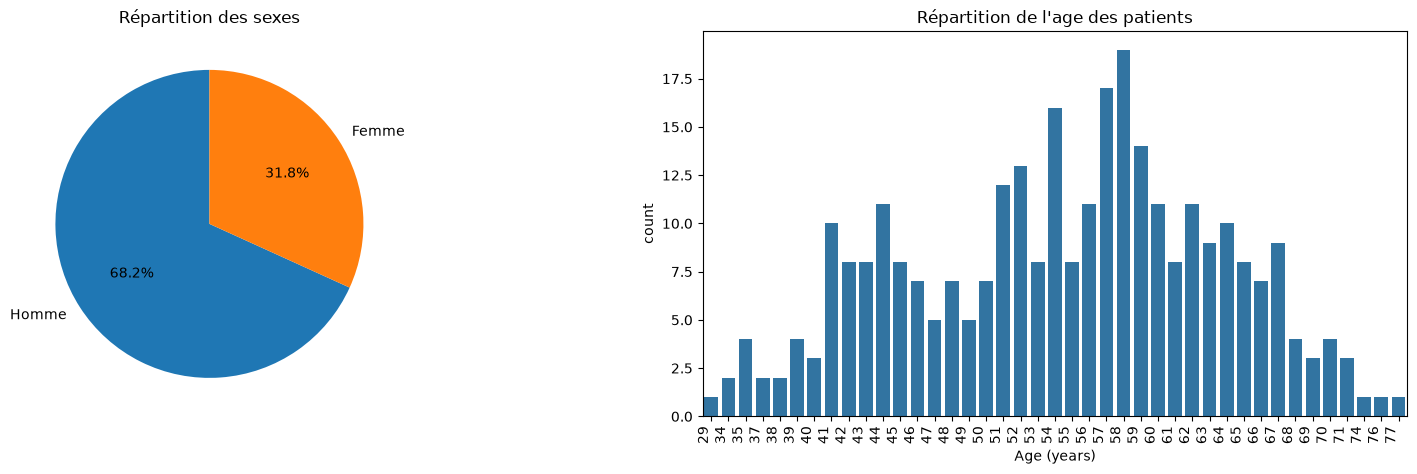

In [17]:
fig, ax = plt.subplots(1,2,figsize=(20, 5))
ax[0].pie(data_clean['Sex'].value_counts(), labels = ['Homme', 'Femme'], autopct='%1.1f%%', startangle=90)
ax[0].set_title('Répartition des sexes')

sns.countplot(x = 'Age (years)', data = data_clean, ax = ax[1]).set_title("Répartition de l'age des patients")
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=90, ha='right')

## IV - Split Train / Test

## V - Prétraitement des données

Comme nous avant plusieurs étapes de traitements de nos données à effectuer, nous allons confectionner
un pipeline afin de regrouper toutes ces étapes en une, comme ça plus tard nous pourrons gagner en temps.
Aussi, nous allons répertorier les différents résultats possibles dans chacunes des colonnes avec des données de type discret.